# **A. Import Library**

In [ ]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
!pip install -q langdetect deep-translator kagglehub wordcloud
import kagglehub
import langdetect
langdetect.DetectorFactory.seed = 42

import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
# LOAD DATASET
# ============

path = kagglehub.dataset_download("andrewmvd/cyberbullying-classification")
df = pd.read_csv(os.path.join(path, "cyberbullying_tweets.csv"))
print("Data Volume:", len(df))

Using Colab cache for faster access to the 'cyberbullying-classification' dataset.
Data Volume: 47692


In [ ]:
print("Amount of Rows and Columns :", df.shape)

Amount of Rows and Columns : (47692, 2)


# **B. Data Cleaning**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47692 entries, 0 to 47691
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   tweet_text          47692 non-null  object
 1   cyberbullying_type  47692 non-null  object
dtypes: object(2)
memory usage: 745.3+ KB


In [ ]:
df.describe(include='all')

,tweet_text,cyberbullying_type
count,47692,47692
unique,46017,6
top,Going to see @TheQuinnspiracy's movie I AM SO ...,religion
freq,2,7998


**Note : Ada perbedaan antara hasil count dan unique nya, sehingga memunculkan dugaan bahwa ada tweet text yang duplikat.**

In [ ]:
# Most frequent tweet (Top 10)
df["tweet_text"].value_counts().head(10)

,count
tweet_text,
Going to see @TheQuinnspiracy's movie I AM SO EXCITED,2
This show is officially fucked!!!!! Space Cadets get to stay FFS #MKR,2
I am right now watching Enforcers defend Chums on facebook.,2
@NedGilmore i think it was clefthoof meat?,2
"NPR asked to speak to me about the wadhwa thing. They *just* got off the phone with him, &amp; now they don't need to talk to me anymore. Weird.",2
"In many states, we've got laws that specifically protect against this kind of thing. However, they aren't enforced due to education/funding.",2
"@PeerWorker you made a false equivalency, I called it on you, and you threatened financial consequences.",2
@mikeage what isn't? ;P,2
@erinjmccarty YUP. Clemson Uni.,2


**Note : Dari tabel di atas terlihat ada duplikat tweet text, sehingga perlu dihapus dari data.**

In [ ]:
# Calculate duplicated tweet
duplicates = df.duplicated(subset=["tweet_text"]).sum()
print("Total duplicates:", duplicates)

Total duplicates: 1675


In [ ]:
# Mengecek missing value

df.isnull().sum()

,0
tweet_text,0
cyberbullying_type,0


In [ ]:
df['cyberbullying_type'].value_counts()

,count
cyberbullying_type,
religion,7998
age,7992
gender,7973
ethnicity,7961
not_cyberbullying,7945
other_cyberbullying,7823


In [ ]:
df["tweet_length"] = df["tweet_text"].apply(len)

# Checking the longest and shortest tweet
max_len = df["tweet_length"].max()
min_len = df["tweet_length"].min()

print(f"The length of longest tweet: {max_len} caracters")
print(f"The length of shortest tweet : {min_len} caracters")

The length of longest tweet: 5018 caracters
The length of shortest tweet : 1 caracters


In [ ]:
# Deleting duplicates
df = df.drop_duplicates(subset=["tweet_text"]).reset_index(drop=True)
print("Data Volume after dropping duplicates:", len(df))

Data Volume after dropping duplicates: 46017


In [ ]:
# Filter english only
def is_indonesian(text):
    try:
        return langdetect.detect(text) == "id"
    except Exception:
        return False

df["is_id"] = df["tweet_text"].apply(is_indonesian)
df = df[~df["is_id"]].drop(columns=["is_id"]).reset_index(drop=True)
print("Data volume after filtering:", len(df))

Data volume after filtering: 45824


In [ ]:
# Tweet length & Checking after clearing emoji
df["tweet_length"] = df["tweet_text"].apply(len)

def sisa_isi_setelah_bersih(text):
    hanya_huruf_angka = re.sub(r"[^\w\s]", "", text)
    return hanya_huruf_angka.strip()

df["cek_isi"] = df["tweet_text"].apply(sisa_isi_setelah_bersih)
df["cek_isi_length"] = df["cek_isi"].apply(len)

# Amount of meaningless short tweets
benar_benar_kosong = df[(df["tweet_length"] < 5) & (df["cek_isi_length"] < 2)]
print("\n Meaningless short tweets:", len(benar_benar_kosong))

# Extreme long tweets
BATAS_EKSTREM = 1000
outlier_ekstrem = df[df["tweet_length"] > BATAS_EKSTREM]
print(f"Extreme long tweets (>{BATAS_EKSTREM} caracters):", len(outlier_ekstrem))



 Meaningless short tweets: 8
Extreme long tweets (>1000 caracters): 13


In [ ]:
# Final filtering
df = df[
    ~(df["tweet_text"].isin(benar_benar_kosong["tweet_text"])) &
    (df["tweet_length"] <= BATAS_EKSTREM)
].reset_index(drop=True)

df = df.drop(columns=["cek_isi", "cek_isi_length", "tweet_length"])

print(f"\n Final Data Volume after cleaning: {len(df)}")
print(df["cyberbullying_type"].value_counts())


 Final Data Volume after cleaning: 45803
cyberbullying_type
age                    7990
religion               7987
ethnicity              7918
gender                 7877
not_cyberbullying      7817
other_cyberbullying    6214
Name: count, dtype: int64


In [ ]:
# Tweet length (in caracters)
df["_len_check"] = df["tweet_text"].apply(len)

print("=== Longest Tweets (Top 5) ===")
print(df.sort_values("_len_check", ascending=False)[["tweet_text", "cyberbullying_type", "_len_check"]].head(5))

print("\n=== Shortest tweets (Top 5) ===")
print(df.sort_values("_len_check", ascending=True)[["tweet_text", "cyberbullying_type", "_len_check"]].head(5))

print(f"\n Max of length: {df['_len_check'].max()} caracters")
print(f"Min of length : {df['_len_check'].min()} caracters")
print(f"Average        : {df['_len_check'].mean():.1f} caracters")
print(f"Median           : {df['_len_check'].median()} caracters")

df = df.drop(columns=["_len_check"])  # cleaning temp column

=== Longest Tweets (Top 5) ===
                                              tweet_text   cyberbullying_type  \
24880  @Sweetie_Niesha: So Im getting bullied via twi...  other_cyberbullying   
25301  If cats looked like frogs we'd realize what na...  other_cyberbullying   
4765   @andrea_gcav: @viviaanajim recuerdas como noso...    not_cyberbullying   
42426  @JasmineLovvee If He Dont Want You Well Fuck H...            ethnicity   
31004  (2/2) The MO State Constitution (Art. VI sec 1...                  age   

       _len_check  
24880         967  
25301         916  
4765          845  
42426         767  
31004         575  

=== Shortest tweets (Top 5) ===
      tweet_text   cyberbullying_type  _len_check
327          FFS    not_cyberbullying           3
26991        My.  other_cyberbullying           3
23905        Ok.  other_cyberbullying           3
24843        Oh.  other_cyberbullying           3
7251        ROFL    not_cyberbullying           4

 Max of length: 967 caracter

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45803 entries, 0 to 45802
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   tweet_text          45803 non-null  object
 1   cyberbullying_type  45803 non-null  object
dtypes: object(2)
memory usage: 715.8+ KB


In [ ]:
df.isnull().sum()

,0
tweet_text,0
cyberbullying_type,0


In [ ]:
# Checking duplicates
jumlah_duplikat = df.duplicated(subset=["tweet_text"]).sum()
print("Total duplicates:", jumlah_duplikat)

Total duplicates: 0


In [ ]:
# PREPROCESSING TEKS (KHUSUS ROBERTA)

def clean_text_for_roberta(text):
    text = str(text)
    text = re.sub(r"http\S+", "", text)       # drop URL
    text = re.sub(r"\s+", " ", text).strip()  # drop whitespaces
    return text

df["clean_text"] = df["tweet_text"].apply(clean_text_for_roberta)
df = df[df["clean_text"].str.strip() != ""].reset_index(drop=True)
print("Data Volume after preprocessing:", len(df))

Data Volume after preprocessing: 45717


# **C. Exploratory Data Analysis (EDA)**

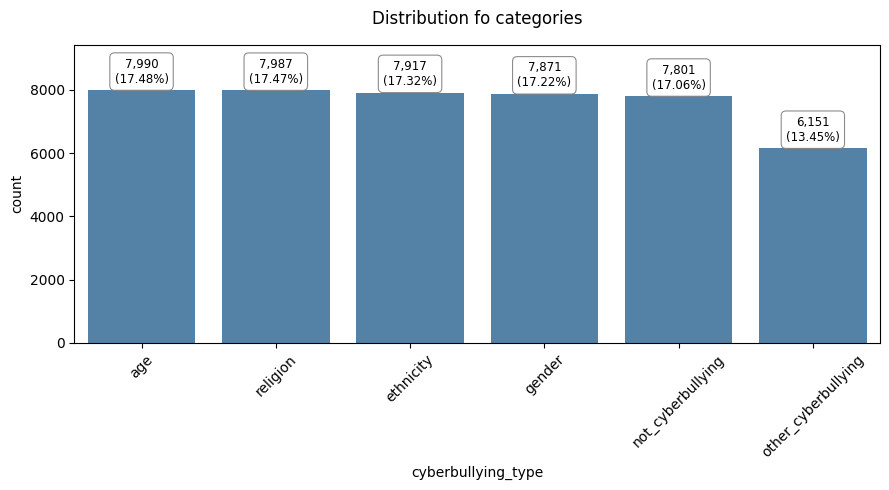

In [ ]:
# Distribution (count + percentage)
label_counts = df["cyberbullying_type"].value_counts()
label_pct = (label_counts / len(df) * 100).round(2)

plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df, x="cyberbullying_type", order=label_counts.index, color="steelblue")

ax.set_ylim(0, max(label_counts) * 1.18)

# Iteration
for p, kategori in zip(ax.patches, label_counts.index):
    tinggi = p.get_height()
    teks = f"{int(tinggi):,}\n({label_pct[kategori]}%)"

    ax.annotate(
        teks,
        (p.get_x() + p.get_width() / 2., tinggi + 150),
        ha="center", va="bottom", fontsize=8.5,
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor="gray",
            linewidth=0.8,
            alpha=0.9
        )
    )

plt.xticks(rotation=45)
plt.title("Distribution fo categories", pad=15)
plt.tight_layout()
plt.show()

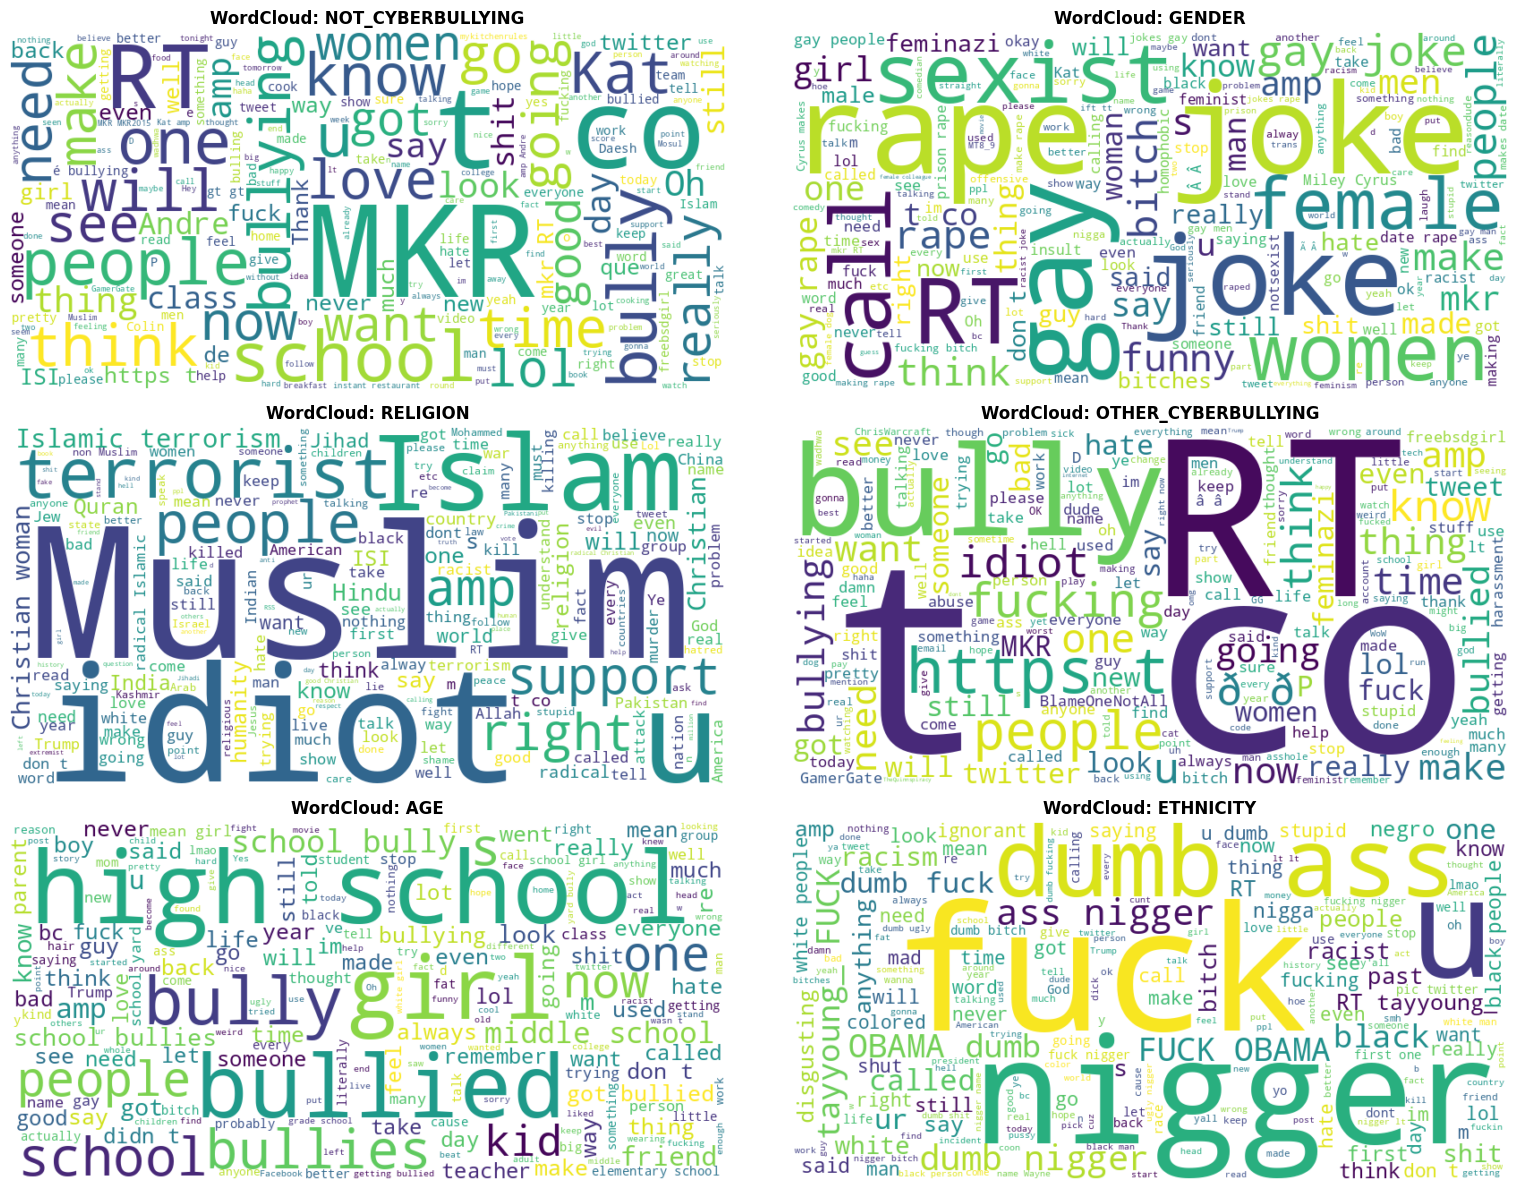

In [ ]:
# Word Cloud of categories

categories = df["cyberbullying_type"].unique()
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
axes = axes.flatten()
for i, cat in enumerate(categories):
    text_cat = " ".join(df[df["cyberbullying_type"] == cat]["tweet_text"])
    wc = WordCloud(width=800, height=400, background_color="white").generate(text_cat)
    axes[i].imshow(wc, interpolation="bilinear")
    axes[i].set_title(f"WordCloud: {cat.upper()}", fontsize=12, fontweight="bold")
    axes[i].axis("off")
plt.tight_layout()
plt.show()

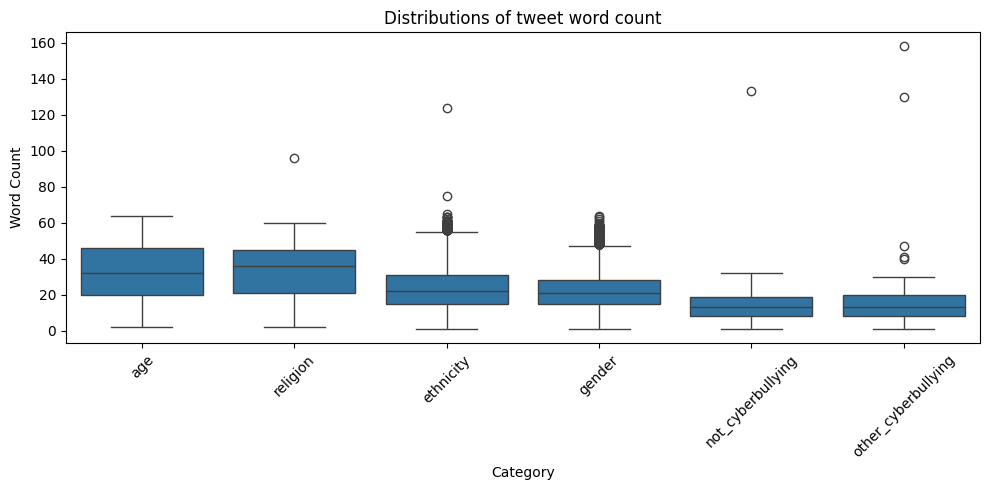


=== Averages of Tweet Word Count ===
cyberbullying_type
not_cyberbullying      13.5
other_cyberbullying    13.8
gender                 23.5
ethnicity              24.8
age                    32.3
religion               33.4
Name: word_count_eda, dtype: float64


In [ ]:
# Distribution of word count per category
df["word_count_eda"] = df["clean_text"].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="cyberbullying_type", y="word_count_eda", order=label_counts.index)
plt.xticks(rotation=45)
plt.title("Distributions of tweet word count")
plt.xlabel("Category")
plt.ylabel("Word Count")
plt.tight_layout()
plt.show()

print("\n=== Averages of Tweet Word Count ===")
print(df.groupby("cyberbullying_type")["word_count_eda"].mean().round(1).sort_values())

config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

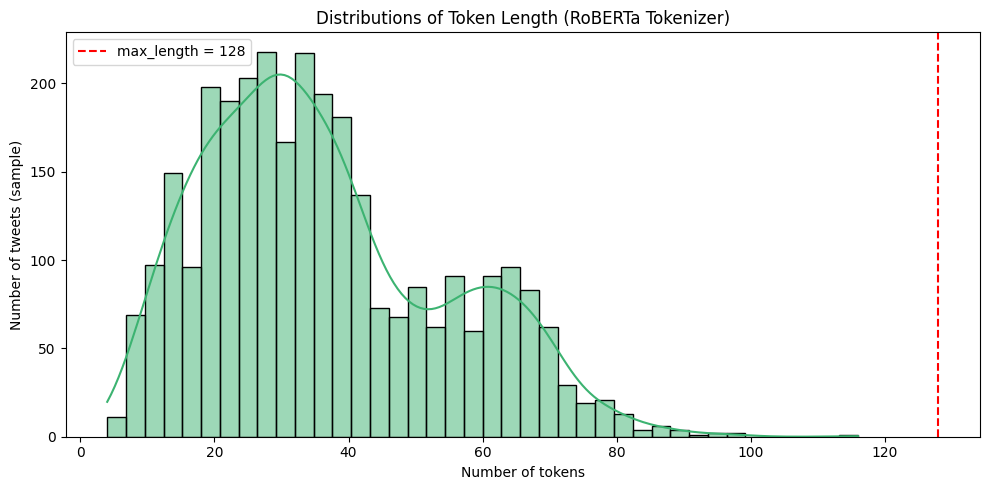


Persentage of tweets (sample) > 128 (cutting point): 0.00%


In [ ]:
# Distributions of Token length after tokenizer RoBERTa ----
# max_length tokenizer (128).
# Cutting > 128 before Modeling.

from transformers import AutoTokenizer as _AutoTokenizerEDA
_tokenizer_eda = _AutoTokenizerEDA.from_pretrained("distilroberta-base")

sample_for_token_eda = df["clean_text"].sample(min(3000, len(df)), random_state=42)
token_lengths = sample_for_token_eda.apply(lambda x: len(_tokenizer_eda.encode(x)))

plt.figure(figsize=(10, 5))
sns.histplot(token_lengths, bins=40, kde=True, color="mediumseagreen")
plt.axvline(128, color="red", linestyle="--", label="max_length = 128")
plt.title("Distributions of Token Length (RoBERTa Tokenizer)")
plt.xlabel("Number of tokens")
plt.ylabel("Number of tweets (sample)")
plt.legend()
plt.tight_layout()
plt.show()

pct_terpotong = (token_lengths > 128).mean() * 100
print(f"\nPersentage of tweets (sample) > 128 (cutting point): {pct_terpotong:.2f}%")

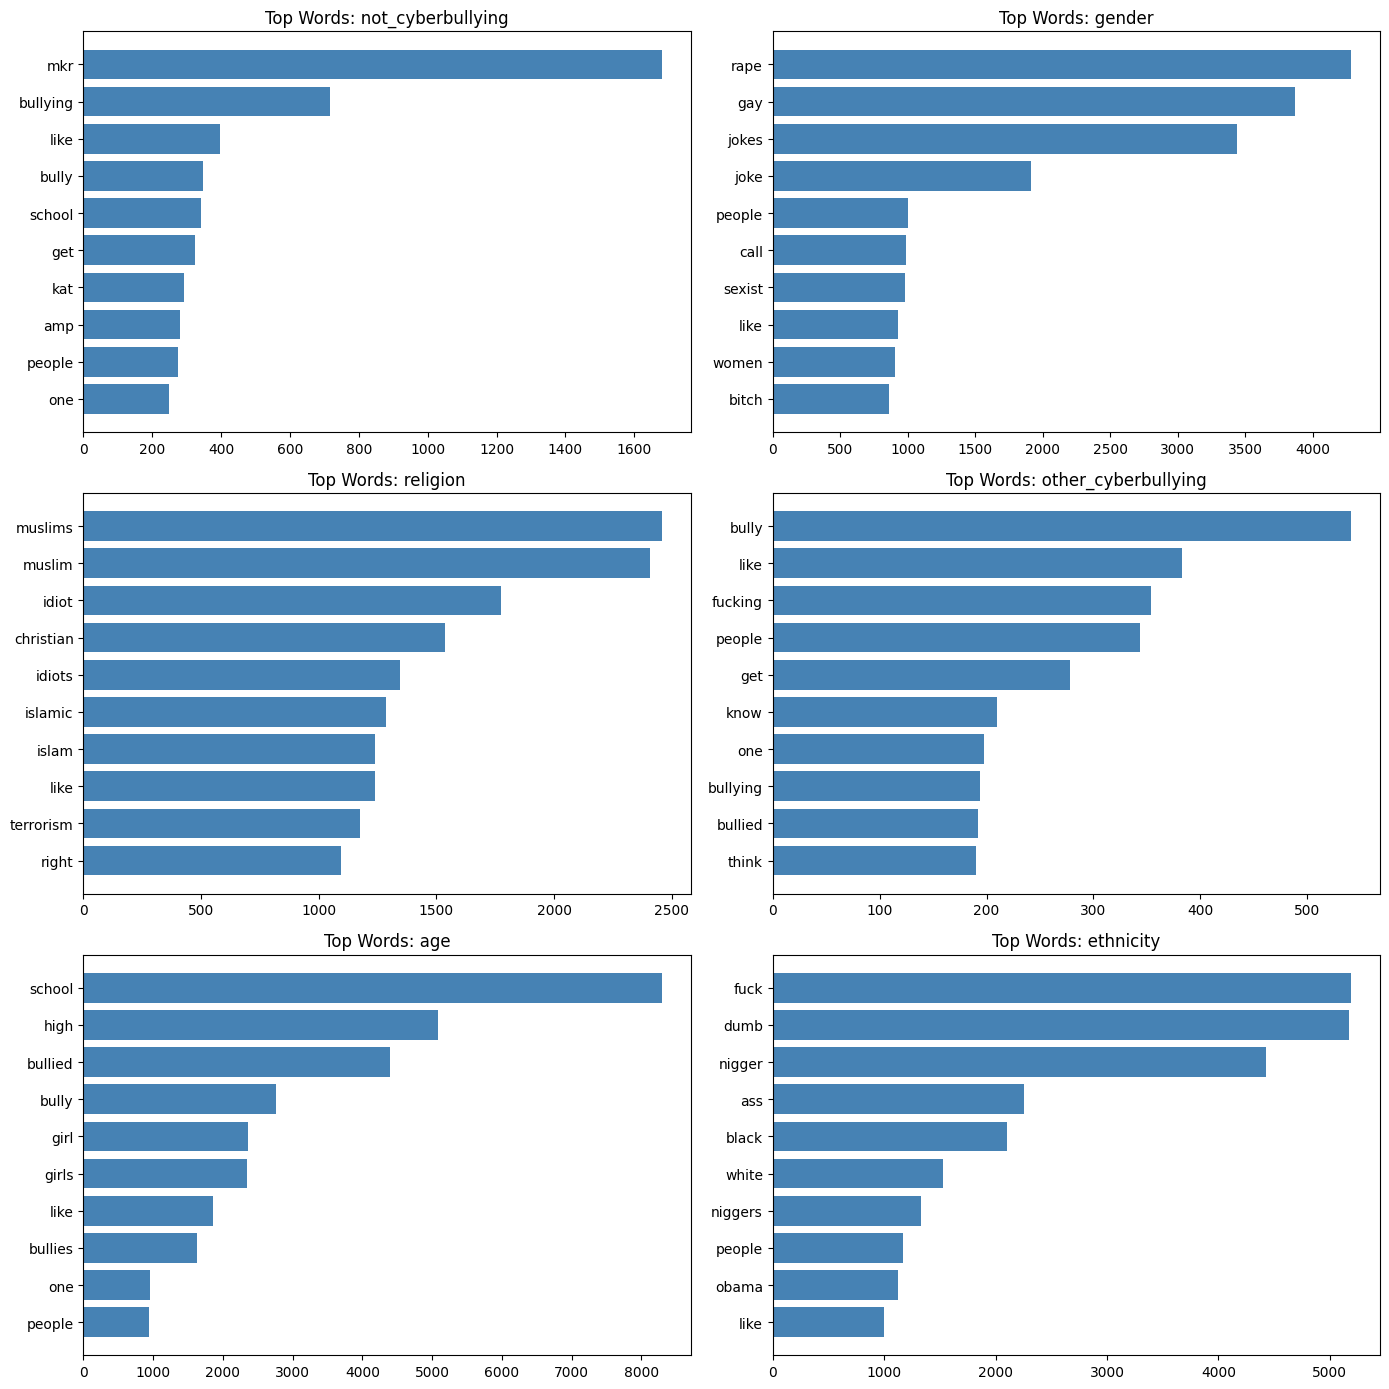

In [ ]:
# Top words per category (bar chart)
from collections import Counter
import re as _re_eda

stop_words_eda = set(stopwords.words("english")) if "stopwords" in dir() else set()

def top_words(text_series, n=10):
    words = []
    for t in text_series:
        tokens = _re_eda.findall(r"[a-zA-Z]+", t.lower())
        words.extend([w for w in tokens if w not in stop_words_eda and len(w) > 2])
    return Counter(words).most_common(n)

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()
for i, cat in enumerate(categories):
    teks_kategori = df[df["cyberbullying_type"] == cat]["clean_text"]
    top10 = top_words(teks_kategori, n=10)
    if top10:
        kata, jumlah = zip(*top10)
        axes[i].barh(kata[::-1], jumlah[::-1], color="steelblue")
        axes[i].set_title(f"Top Words: {cat}")
plt.tight_layout()
plt.show()

In [ ]:
df.describe(include='all')

,tweet_text,cyberbullying_type,clean_text,word_count_eda
count,45717,45717,45717,45717.000000
unique,45717,6,45472,NaN
top,Bro. U gotta chill RT @CHILLShrammy: Dog FUCK ...,age,#MileyCyrus Miley Cyrus causes controversy wit...,NaN
freq,1,7990,17,NaN
mean,NaN,NaN,NaN,23.982217
std,NaN,NaN,NaN,14.283357
min,NaN,NaN,NaN,1.000000
25%,NaN,NaN,NaN,13.000000
50%,NaN,NaN,NaN,21.000000
75%,NaN,NaN,NaN,33.000000


In [ ]:
# Dropping duplicates after cleaning
df = df.drop_duplicates(subset=["clean_text"], keep="first").reset_index(drop=True)

# Re-Checking dataframe
df.describe(include='all')

,tweet_text,cyberbullying_type,clean_text,word_count_eda
count,45472,45472,45472,45472.000000
unique,45472,6,45472,NaN
top,"This dude said ""dumb sosh nigger fuck""",religion,"This dude said ""dumb sosh nigger fuck""",NaN
freq,1,7975,1,NaN
mean,NaN,NaN,NaN,24.043631
std,NaN,NaN,NaN,14.288281
min,NaN,NaN,NaN,1.000000
25%,NaN,NaN,NaN,13.000000
50%,NaN,NaN,NaN,21.000000
75%,NaN,NaN,NaN,34.000000


**Note : All data is balanced**

# **D.Split Data Train-Test, Encoding**

In [ ]:
# LABEL STAGE 1 & STAGE 2

df["stage1_label"] = df["cyberbullying_type"].apply(lambda x: 0 if x == "not_cyberbullying" else 1)

In [ ]:
# =========================================================
# D. TRAIN TEST SPLIT -
# =========================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

# 1. Main splitting
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["cyberbullying_type"]
)

# ---- Stage 1 (Binary: Cyberbullying vs Not) ----
X_train_s1 = train_df["clean_text"]
y_train_s1 = train_df["stage1_label"]
X_test_s1 = test_df["clean_text"]
y_test_s1 = test_df["stage1_label"]

print("\n=== DISTRIBUSI STAGE 1 (TRAIN) ===")
print(y_train_s1.value_counts())

# ---- Stage 2 (Multi-class: Bullying Category only) ----
# Filter subset train & test
train_df_stage2 = train_df[train_df["cyberbullying_type"] != "not_cyberbullying"].copy()
test_df_stage2 = test_df[test_df["cyberbullying_type"] != "not_cyberbullying"].copy()

# Label Encoding
le_stage2 = LabelEncoder()
train_df_stage2 = train_df_stage2.assign(
    stage2_label=le_stage2.fit_transform(train_df_stage2["cyberbullying_type"])
)
test_df_stage2 = test_df_stage2.assign(
    stage2_label=le_stage2.transform(test_df_stage2["cyberbullying_type"])
)

X_train_s2 = train_df_stage2["clean_text"]
y_train_s2 = train_df_stage2["stage2_label"]
X_test_s2 = test_df_stage2["clean_text"]
y_test_s2 = test_df_stage2["stage2_label"]

print("\n=== DISTRIBUSI STAGE 2 (TRAIN) ===")
print(train_df_stage2["cyberbullying_type"].value_counts())

# Simple Label Mapping
label_mapping = dict(enumerate(le_stage2.classes_))
print("\nLabel Mapping stage 2:", label_mapping)


=== DISTRIBUSI STAGE 1 (TRAIN) ===
stage1_label
1    30175
0     6202
Name: count, dtype: int64

=== DISTRIBUSI STAGE 2 (TRAIN) ===
cyberbullying_type
religion               6380
age                    6376
ethnicity              6329
gender                 6193
other_cyberbullying    4897
Name: count, dtype: int64

Label Mapping stage 2: {0: 'age', 1: 'ethnicity', 2: 'gender', 3: 'other_cyberbullying', 4: 'religion'}


# **E. Model Machine Learning**

## **RoBERTa 2 Stages Classification**

In [ ]:
# Added Libraries --  TOKENIZER, MODEL, TRAINING, & AUGMENTATION
# ============================================================
import time
import torch
import torch.nn.functional as F

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
)
from datasets import Dataset

from deep_translator import GoogleTranslator

In [ ]:
!pip install -q deep-translator

In [ ]:
# E. TOKENIZER & METRICS FUNCTION

model_name = "distilroberta-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

def tokenize_function(examples):
    return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=128)

def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average="macro")
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc, "f1": f1, "precision": precision, "recall": recall}

Using device: cuda


In [ ]:
# TRAINING STAGE 1 (BULLYING VS NOT)

from sklearn.metrics import classification_report

# 1. Dropping 'text', PyTorch dataset clean from strings
ds_train_s1 = Dataset.from_dict({
    "text": X_train_s1.tolist(),
    "label": y_train_s1.tolist()
}).map(tokenize_function, batched=True, remove_columns=["text"])

ds_test_s1 = Dataset.from_dict({
    "text": X_test_s1.tolist(),
    "label": y_test_s1.tolist()
}).map(tokenize_function, batched=True, remove_columns=["text"])

# 2. Initiation of Model Stage 1
model_s1 = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

# 3. Training Arguments
args_s1 = TrainingArguments(
    output_dir="./results_stage1",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    fp16=True,
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="f1"
)

# 4. Initiation of Trainer
trainer_s1 = Trainer(
    model=model_s1,
    args=args_s1,
    train_dataset=ds_train_s1,
    eval_dataset=ds_test_s1,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

# 5. Training & Evaluation
trainer_s1.train()

pred_s1_output = trainer_s1.predict(ds_test_s1)
y_pred_s1 = np.argmax(pred_s1_output.predictions, axis=1)

print("\n=== CLASSIFICATION REPORT STAGE 1 ===")
print(classification_report(
    y_test_s1,
    y_pred_s1,
    target_names=["not_cyberbullying", "cyberbullying"]
))

Map:   0%|          | 0/36377 [00:00<?, ? examples/s]

Map:   0%|          | 0/9095 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

...

Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.270775,0.223016,0.892358,0.799807,0.817332,0.785299
2,0.179882,0.228070,0.896756,0.817669,0.817425,0.817913
3,0.139703,0.261922,0.897526,0.811765,0.825097,0.800194


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


=== CLASSIFICATION REPORT STAGE 1 ===
                   precision    recall  f1-score   support

not_cyberbullying       0.70      0.70      0.70      1551
    cyberbullying       0.94      0.94      0.94      7544

         accuracy                           0.90      9095
        macro avg       0.82      0.82      0.82      9095
     weighted avg       0.90      0.90      0.90      9095



# **E. Data Evaluation**

In [ ]:
# TRAINING STAGE 2 (BULLYING CATEGORIES) -- BASELINE

# 1. Mapping dataset by dropping text column
ds_train_s2 = Dataset.from_dict({
    "text": X_train_s2.tolist(),
    "label": y_train_s2.tolist()
}).map(tokenize_function, batched=True, remove_columns=["text"])

ds_test_s2 = Dataset.from_dict({
    "text": X_test_s2.tolist(),
    "label": y_test_s2.tolist()
}).map(tokenize_function, batched=True, remove_columns=["text"])

# 2. Initiation of Model
model_s2 = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(le_stage2.classes_)
)

# 3. Training Arguments
args_s2 = TrainingArguments(
    output_dir="./results_stage2",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    fp16=True,
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
)

# 4. Trainer dengan Tokenizer
trainer_s2 = Trainer(
    model=model_s2,
    args=args_s2,
    train_dataset=ds_train_s2,
    eval_dataset=ds_test_s2,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

trainer_s2.train()

Map:   0%|          | 0/30175 [00:00<?, ? examples/s]

Map:   0%|          | 0/7544 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: distilroberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.169709,0.156891,0.957847,0.954758,0.954458,0.955152
2,0.105849,0.156027,0.961957,0.959167,0.959303,0.959089
3,0.105551,0.159744,0.964210,0.961271,0.961590,0.961020


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=5658, training_loss=0.14891639831168108, metrics={'train_runtime': 424.8295, 'train_samples_per_second': 213.085, 'train_steps_per_second': 13.318, 'total_flos': 2998063205856000.0, 'train_loss': 0.14891639831168108, 'epoch': 3.0})


=== CLASSIFICATION REPORT PER CATEGORY (STAGE 2, BASELINE) ===
                     precision    recall  f1-score   support

                age     0.9930    0.9856    0.9893      1594
          ethnicity     0.9854    0.9836    0.9845      1582
             gender     0.9317    0.9516    0.9415      1548
other_cyberbullying     0.9097    0.8963    0.9030      1225
           religion     0.9881    0.9881    0.9881      1595

           accuracy                         0.9642      7544
          macro avg     0.9616    0.9610    0.9613      7544
       weighted avg     0.9643    0.9642    0.9642      7544



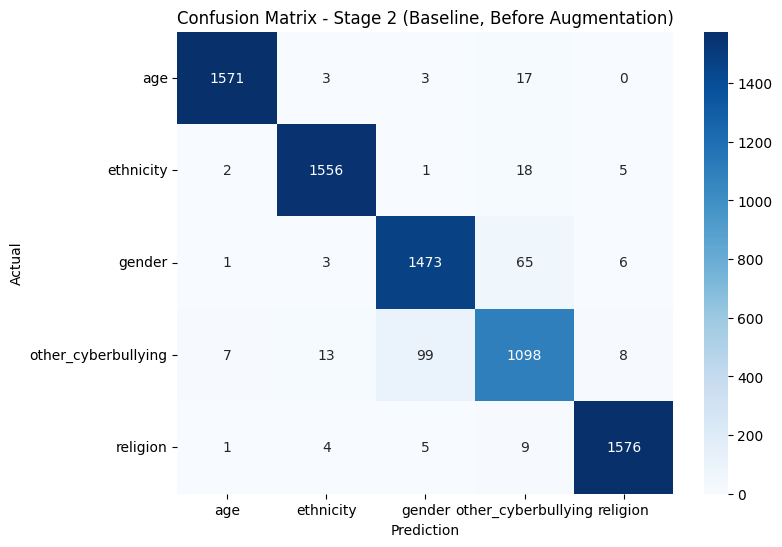

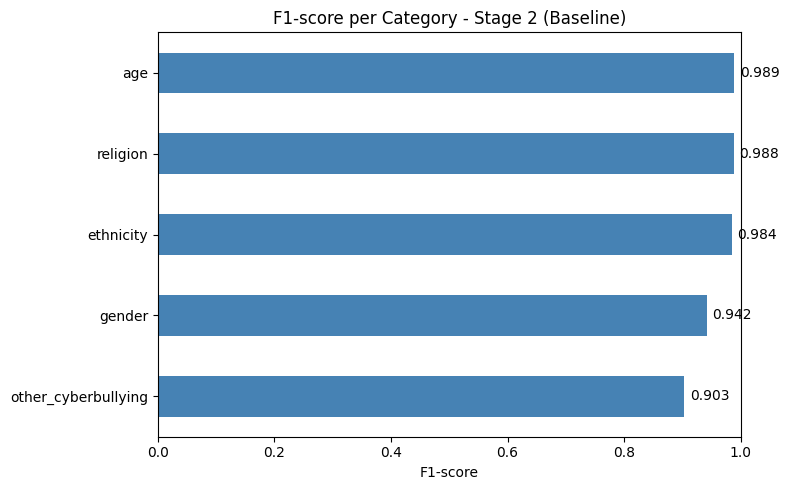

In [ ]:
# EVALUASI PER-CATEGORY STAGE 2

pred_s2_output = trainer_s2.predict(ds_test_s2)
y_pred_s2 = np.argmax(pred_s2_output.predictions, axis=1)
y_true_s2 = pred_s2_output.label_ids

print("\n=== CLASSIFICATION REPORT PER CATEGORY (STAGE 2, BASELINE) ===")
print(classification_report(y_true_s2, y_pred_s2, target_names=le_stage2.classes_, digits=4))

cm = confusion_matrix(y_true_s2, y_pred_s2)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le_stage2.classes_, yticklabels=le_stage2.classes_)
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Stage 2 (Baseline, Before Augmentation)")
plt.show()

# Bar chart F1-score per category
report_dict_baseline = classification_report(
    y_true_s2, y_pred_s2, target_names=le_stage2.classes_, output_dict=True
)
f1_per_kategori_baseline = pd.Series(
    {k: v["f1-score"] for k, v in report_dict_baseline.items() if k in le_stage2.classes_}
).sort_values()

plt.figure(figsize=(8, 5))
ax = f1_per_kategori_baseline.plot(kind="barh", color="steelblue")
plt.xlabel("F1-score")
plt.title("F1-score per Category - Stage 2 (Baseline)")
plt.xlim(0, 1)
for i, v in enumerate(f1_per_kategori_baseline):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.tight_layout()
plt.show()

In [ ]:
# PIPELINE PREDICTION FINAL 2-STAGE

stage2_mapping = dict(enumerate(le_stage2.classes_))

def predict_2stage(text, threshold_s1=0.40, model_stage2=None):
    model_s1.eval()
    model_s2.eval()


    cleaned = clean_text_for_roberta(text)
    inputs = tokenizer(cleaned, return_tensors="pt", padding=True, truncation=True, max_length=128)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        out_s1 = model_s1(**inputs)
        prob_bullying = F.softmax(out_s1.logits, dim=1)[0][1].item()

        if prob_bullying < threshold_s1:
            return "not_cyberbullying"

        out_s2 = model_s2(**inputs)
        pred_s2 = torch.argmax(out_s2.logits, dim=1).item()
        return stage2_mapping[pred_s2]


In [ ]:
# TESTING

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

test_cases = [
    # Kategori: age (0)
    "i was constantly bullied in high school by the popular kids every day",
    "middle school bullies are literally the most cruel and evil people",
    "getting bullied at school destroyed my self esteem when i was young",

    # Kategori: ethnicity (1)
    "black people are useless and ruining this whole country go away",
    "white people have no culture and ruin every neighborhood they join",
    "Go back to your own country you dirty illegal immigrant",

    # Kategori: gender (2)
    "women are dumb bitches and should never be allowed in politics",
    "he is such a weak pathetic man acting like a dramatic emotional girl",
    "dumb blonde girls shouldn't be allowed to work in engineering",

    # Kategori: religion (3)
    "muslims are all radical terrorists who destroy peace everywhere",
    "jewish people control everything and ruin the world economy",
    "christian fanatics are pushing their stupid brainwashing cult on us",

    # Kategori: other_cyberbullying (4)
    "shut up you pathetic loser stop crying online like a whiny baby",
    "you are so ugly and fake nobody will ever like you delete your account",
    "stop posting garbage content you are completely useless and talentless",

    # Kategori: not_cyberbullying (5)
    "had a great time at the park today with my friends and family",
    "i deeply respect older people and their incredible life wisdom",
    "Your recent video was really helpful and well explained, keep it up!",
    "happy birthday to my little brother hope you have an awesome day",
    "agree to disagree on this political topic but thanks for the discussion"
]

results = []

# Jalankan inferensi menggunakan fungsi pipeline 2-stage
for text in test_cases:
    hasil_prediksi = predict_2stage(text, threshold_s1=0.40)

    results.append({
        "Text Tweet": text,
        "Predicted Category": hasil_prediksi
    })

# Tampilkan hasil ke dalam dataframe
df_results_perfect = pd.DataFrame(results)
pd.set_option('display.max_colwidth', None)
df_results_perfect

,Text Tweet,Predicted Category
0,i was constantly bullied in high school by the popular kids every day,age
1,middle school bullies are literally the most cruel and evil people,age
2,getting bullied at school destroyed my self esteem when i was young,age
3,black people are useless and ruining this whole country go away,ethnicity
4,white people have no culture and ruin every neighborhood they join,ethnicity
5,Go back to your own country you dirty illegal immigrant,ethnicity
6,women are dumb bitches and should never be allowed in politics,gender
7,he is such a weak pathetic man acting like a dramatic emotional girl,gender
8,dumb blonde girls shouldn't be allowed to work in engineering,gender
9,muslims are all radical terrorists who destroy peace everywhere,religion


# SAVE MODEL

In [ ]:
# Saving Model Stage 1 & Tokenizer
trainer_s1.save_model("./saved_models/stage1_model")
tokenizer.save_pretrained("./saved_models/stage1_model")

# Saving Model Stage 2
trainer_s2.save_model("./saved_models/stage2_model")
tokenizer.save_pretrained("./saved_models/stage2_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./saved_models/stage2_model/tokenizer_config.json',
 './saved_models/stage2_model/tokenizer.json')

In [ ]:
%%writefile requirements.txt
streamlit
torch
transformers
datasets
scikit-learn
deep-translator
pandas
numpy

Writing requirements.txt


In [ ]:
!pip install -q streamlit

In [ ]:
%%writefile app.py
import streamlit as st
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

st.set_page_config(page_title="Cyberbullying Detection", layout="centered")

st.title("🛡️ Cyberbullying Detection App")
st.write("Detector App by Using Classification Model 2-Stage RoBERTa.")

# Load Model & Tokenizer
@st.cache_resource
def load_models():
    tok = AutoTokenizer.from_pretrained("./saved_models/stage1_model")
    model_s1 = AutoModelForSequenceClassification.from_pretrained("./saved_models/stage1_model")
    model_s2 = AutoModelForSequenceClassification.from_pretrained("./saved_models/stage2_model")
    return tok, model_s1, model_s2

tokenizer, model_s1, model_s2 = load_models()

# Mapping Stage 1 & 2
stage1_labels = ["not_cyberbullying", "cyberbullying"] # Sesuai target_names stage 1
stage2_labels = ["age", "ethnicity", "gender", "other_cyberbullying", "religion"] # Sesuaikan dengan le_stage2.classes_

# Input Tweets
user_input = st.text_area("Typing tweet text:", "")

if st.button("Text analysis"):
    if user_input.strip() == "":
        st.warning("Input text first!")
    else:
        # Preprocessing & Inference Stage 1
        inputs = tokenizer(user_input, return_tensors="pt", truncation=True, padding="max_length", max_length=128)

        with torch.no_grad():
            out_s1 = model_s1(**inputs)
            pred_s1_idx = torch.argmax(out_s1.logits, dim=1).item()
            pred_s1_label = stage1_labels[pred_s1_idx]

        st.subheader("Analysis result:")

        if pred_s1_label == "not_cyberbullying":
            st.success("✅ **Result of Stage 1:** Not Cyberbullying")
        else:
            st.error("⚠️ **Result of Stage 1:** Cyberbullying!")

            # Predict Stage 2 (Bullying Category)
            with torch.no_grad():
                out_s2 = model_s2(**inputs)
                pred_s2_idx = torch.argmax(out_s2.logits, dim=1).item()
                pred_s2_label = stage2_labels[pred_s2_idx]

            st.warning(f"🏷️ **Result of Stage 2 (Category):** {pred_s2_label.capitalize()}")

Writing app.py


In [ ]:
import shutil
shutil.make_archive('saved_models', 'zip', 'saved_models')

'/content/saved_models.zip'

In [ ]:
from huggingface_hub import HfApi, login

login(token="")

api = HfApi()

# 2. Upload model stage 1
api.create_repo(repo_id="wandaestu/stage1-cyberbullying", repo_type="model", exist_ok=True)
api.upload_folder(
    folder_path="./saved_models/stage1_model",
    repo_id="wandaestu/stage1-cyberbullying",
    repo_type="model"
)

# 3. Upload model stage 2
api.create_repo(repo_id="wandaestu/stage2-cyberbullying", repo_type="model", exist_ok=True)
api.upload_folder(
    folder_path="./saved_models/stage2_model",
    repo_id="wandaestu/stage2-cyberbullying",
    repo_type="model"
)

print("Yeay, upload model to Hugging Face success!")

Yeay, upload model to Hugging Face success!
